# Exoplanet Research: Projects 1 & 2
**What the infographics claim vs what the data says**

Supervisor: Payam Asadinia (ORCID 0009-0002-3953-6104) · LSP · started Nov 2026

| Part | What it does | Who |
|---|---|---|
| **A. Data** | Downloads the confirmed-planet table from the NASA Exoplanet Archive | Run once per session |
| **B. Physics** | Starlight S = L/a², equilibrium temperature, habitable zone (Kopparapu et al. 2014), Earth Similarity Index | Students can check these against hand calculations |
| **C. Project 2** | Selects rocky habitable-zone planets, ranks them by ESI, makes the figure | Main result |
| **D. Project 1** | Looks up any planet named in a viral post, computes % error, checks a whole claims log | Students do most of this |

**How to use:** Runtime → Run all. Part A needs internet (Colab has it). Each run saves dated CSV files, so the paper can quote the exact archive download date.

In [54]:
%pip install -q certifi

Note: you may need to restart the kernel to use updated packages.


## A. Data: download from the NASA Exoplanet Archive

In [55]:
import io, re, difflib, datetime, urllib.parse, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ssl, certifi
SSL_CTX = ssl.create_default_context(cafile=certifi.where())

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

TODAY = datetime.date.today().isoformat()
TAP = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

# pscomppars = one row per confirmed planet, best available value for each column
COLS = ["pl_name", "hostname", "sy_dist", "sy_pnum", "discoverymethod", "disc_year",
        "pl_orbper", "pl_orbsmax", "pl_rade", "pl_bmasse", "pl_bmassprov",
        "pl_insol", "pl_eqt", "pl_orbeccen", "pl_controv_flag", "tran_flag",
        "st_spectype", "st_teff", "st_rad", "st_mass", "st_lum"]

def tap_query(adql):
    url = TAP + "?" + urllib.parse.urlencode({"query": adql, "format": "csv"})
    with urllib.request.urlopen(url, timeout=120, context=SSL_CTX) as r:
        return pd.read_csv(io.StringIO(r.read().decode()))

df_raw = tap_query(f"select {', '.join(COLS)} from pscomppars")
df_raw.to_csv(f"pscomppars_{TODAY}.csv", index=False)
print(f"Downloaded {len(df_raw):,} confirmed planets on {TODAY}")
df_raw.head()

Downloaded 6,473 confirmed planets on 2026-11-22


,pl_name,hostname,sy_dist,sy_pnum,discoverymethod,disc_year,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_bmassprov,pl_insol,pl_eqt,pl_orbeccen,pl_controv_flag,tran_flag,st_spectype,st_teff,st_rad,st_mass,st_lum
0,Kepler-257 d,Kepler-257,780.2560,3,Transit,2014,24.664551,0.160000,4.950000,21.70,M-R relationship,15.200,567.00,0.0,0,1,NaN,5180.0,1.037,0.916,-0.37756
1,TOI-1758 b,TOI-1758,96.6215,1,Transit,2024,20.705075,0.141409,3.620000,6.90,Mass,21.050,551.44,0.0,0,1,NaN,5169.0,0.810,0.880,-0.37263
2,Kepler-607 c,Kepler-607,519.1220,2,Transit,2021,39.676800,0.215070,2.760012,8.05,M-R relationship,8.800,473.00,0.0,0,1,NaN,5244.0,0.888,0.808,-0.38192
3,Kepler-1040 b,Kepler-1040,482.1190,1,Transit,2016,201.121400,0.672490,2.080000,4.98,M-R relationship,2.121,300.00,0.0,0,1,NaN,5694.0,0.960,0.980,-0.04375
4,Kepler-343 b,Kepler-343,927.1930,2,Transit,2014,8.968550,0.088000,2.410000,6.39,M-R relationship,206.072,1024.00,0.0,0,1,NaN,5807.0,1.433,1.055,0.21620


*If the download fails* (archive down, no internet), upload a CSV saved on an earlier run and use:
```python
df_raw = pd.read_csv("pscomppars_YYYY-MM-DD.csv")
```

## B. Physics

**Starlight received** (Earth = 1), from the inverse-square law:
$$S = \frac{L_\star / L_\odot}{(a / 1\,\text{AU})^2}$$
The archive stores `st_lum` as **log₁₀(L/L☉)**, so L = 10^st_lum.

**Equilibrium temperature** (no greenhouse effect, heat spread over the whole planet):
$$T_{eq} = 278.6\,\text{K}\times S^{1/4}\times(1-A)^{1/4}$$
With Earth's albedo A = 0.3 this gives 255 K (−18 °C). Earth is really +15 °C because of the greenhouse effect.

**Habitable zone** (Kopparapu et al. 2014): the boundaries are values of S that depend on the star's temperature:
$$S_{\text{eff}} = S_{\text{eff},\odot} + aT_* + bT_*^2 + cT_*^3 + dT_*^4,\qquad T_* = T_{\text{eff}} - 5780\text{ K}$$
* Conservative HZ: *runaway greenhouse* (inner) → *maximum greenhouse* (outer)
* Optimistic HZ: *recent Venus* (inner) → *early Mars* (outer)
* Valid for 2600 K ≤ T_eff ≤ 7200 K

**Earth Similarity Index** (radius + starlight version, as used by the PHL Habitable Worlds Catalog):
$$\text{ESI} = 1-\sqrt{\tfrac12\left[\left(\frac{R-1}{R+1}\right)^2+\left(\frac{S-1}{S+1}\right)^2\right]}$$
R in Earth radii, S in Earth units. Earth = 1; values ≥ 0.8 are usually called "Earth-like".

In [56]:
EARTH_RADIUS_KM = 12742 / 2
PC_TO_LY = 3.26156

def starlight(log_L, a_au):
    # S = L / a^2   (Earth units)
    return 10**log_L / a_au**2

def t_eq(S, albedo=0.3):
    # equilibrium temperature in kelvin
    return 278.6 * S**0.25 * (1 - albedo)**0.25

# Kopparapu et al. (2014), 1 Earth-mass coefficients: S_eff_sun, a, b, c, d
KOPPARAPU = {
    "recent_venus":       (1.776, 2.136e-4, 2.533e-8, -1.332e-11, -3.097e-15),
    "runaway_greenhouse": (1.107, 1.332e-4, 1.580e-8, -8.308e-12, -1.931e-15),
    "maximum_greenhouse": (0.356, 6.171e-5, 1.698e-9, -3.198e-12, -5.575e-16),
    "early_mars":         (0.320, 5.547e-5, 1.526e-9, -2.874e-12, -5.011e-16),
}

def hz_limit(teff, which):
    s0, a, b, c, d = KOPPARAPU[which]
    t = np.asarray(teff, dtype=float) - 5780
    return s0 + a*t + b*t**2 + c*t**3 + d*t**4

def esi(R, S):
    return 1 - np.sqrt(0.5 * (((R - 1)/(R + 1))**2 + ((S - 1)/(S + 1))**2))

# --- sanity checks: Earth around the Sun -------------------------------
print("Earth S      =", starlight(0.0, 1.0))                       # 1.0
print("Earth T_eq   =", round(float(t_eq(1.0)), 1), "K")           # ~255 K
print("Earth ESI    =", esi(1.0, 1.0))                             # 1.0
print("Sun HZ (S)   : conservative", round(float(hz_limit(5780, 'runaway_greenhouse')), 3),
      "→", round(float(hz_limit(5780, 'maximum_greenhouse')), 3))
print("Sun HZ (AU)  : conservative",
      round(float(1/np.sqrt(hz_limit(5780, 'runaway_greenhouse'))), 2), "→",
      round(float(1/np.sqrt(hz_limit(5780, 'maximum_greenhouse'))), 2))   # ~0.95 → 1.68 AU

Earth S      = 1.0
Earth T_eq   = 254.8 K
Earth ESI    = 1.0
Sun HZ (S)   : conservative 1.107 → 0.356
Sun HZ (AU)  : conservative 0.95 → 1.68


## C. Project 2: rank the rocky habitable-zone planets

**Rules (write these in the paper's Methods):**
1. **S** is computed from L/a² when both are known; otherwise the archive's `pl_insol` is used.
2. **Rocky** means measured radius ≤ 1.6 R⊕ (Rogers 2015). Planets with no radius (found by radial velocity) are kept only if mass ≤ 3 M⊕; their radius is estimated with R = M^0.279 (Chen & Kipping 2017) and flagged. For RV planets the mass is usually a *minimum* mass (M sin i).
3. **HZ** is tested with the Kopparapu limits at the star's own T_eff.

In [57]:
RADIUS_MAX = 1.6      # R_earth
MASS_MAX_NO_RADIUS = 3.0   # M_earth

df = df_raw.copy()

# 1. starlight
S_calc = starlight(df["st_lum"], df["pl_orbsmax"])
df["S"] = S_calc.where(S_calc.notna(), df["pl_insol"])
df["S_source"] = np.where(S_calc.notna(), "L/a^2", np.where(df["pl_insol"].notna(), "archive pl_insol", "none"))

# 2. radius (measured or estimated)
df["R"] = df["pl_rade"]
df["R_source"] = np.where(df["pl_rade"].isna(), "none",
                 np.where(df["tran_flag"] == 1, "measured (transit)", "estimated (archive M-R)"))
est = df["pl_rade"].isna() & df["pl_bmasse"].notna() & (df["pl_bmasse"] <= MASS_MAX_NO_RADIUS)
df.loc[est, "R"] = df.loc[est, "pl_bmasse"] ** 0.279
df.loc[est, "R_source"] = "estimated from mass"

# 3. habitable-zone limits at each star's T_eff
teff = df["st_teff"].clip(2600, 7200)
df["teff_in_range"] = df["st_teff"].between(2600, 7200)
for k in KOPPARAPU:
    df["S_" + k] = hz_limit(teff, k)
df["HZ"] = np.select(
    [(df["S"] <= df["S_runaway_greenhouse"]) & (df["S"] >= df["S_maximum_greenhouse"]),
     (df["S"] <= df["S_recent_venus"]) & (df["S"] >= df["S_early_mars"])],
    ["conservative", "optimistic"], default="outside")
df.loc[df["S"].isna() | df["st_teff"].isna(), "HZ"] = "unknown"

# derived quantities
df["T_eq_K"] = t_eq(df["S"])
df["T_eq_C"] = df["T_eq_K"] - 273.15
df["ESI"] = esi(df["R"], df["S"])
df["dist_ly"] = df["sy_dist"] * PC_TO_LY
df["diameter_km"] = df["R"] * 2 * EARTH_RADIUS_KM

rocky = df["R"] <= RADIUS_MAX
hz = df[rocky & df["HZ"].isin(["conservative", "optimistic"])].copy()
hz = hz.sort_values("ESI", ascending=False).reset_index(drop=True)
hz.index += 1

print(f"All confirmed planets:          {len(df):,}")
print(f"  with S and T_eff known:       {(df['HZ'] != 'unknown').sum():,}")
print(f"  rocky (R ≤ {RADIUS_MAX} R⊕):          {rocky.sum():,}")
print(f"  rocky AND in a habitable zone: {len(hz)}  "
      f"(conservative {sum(hz.HZ=='conservative')}, optimistic-only {sum(hz.HZ=='optimistic')})")

All confirmed planets:          6,473
  with S and T_eff known:       5,873
  rocky (R ≤ 1.6 R⊕):          1,215
  rocky AND in a habitable zone: 32  (conservative 20, optimistic-only 12)


In [58]:
SHOW = ["pl_name", "st_spectype", "st_teff", "dist_ly", "R", "R_source", "S",
        "T_eq_C", "ESI", "HZ", "teff_in_range", "discoverymethod", "pl_controv_flag"]
ranked = hz[SHOW].round({"st_teff": 0, "dist_ly": 1, "R": 2, "S": 2, "T_eq_C": 0, "ESI": 3})
ranked.to_csv(f"P2_rocky_HZ_ranked_{TODAY}.csv", index_label="rank")
ranked.head(25)

,pl_name,st_spectype,st_teff,dist_ly,R,R_source,S,T_eq_C,ESI,HZ,teff_in_range,discoverymethod,pl_controv_flag
1,Teegarden's Star b,M7.0 V,3034.0,12.5,1.05,estimated (archive M-R),1.08,-14.0,0.969,optimistic,True,Radial Velocity,0
2,Kepler-1512 b,NaN,4372.0,528.4,1.18,measured (transit),1.08,-14.0,0.936,optimistic,True,Transit,0
3,TOI-700 d,M2.5 V,3459.0,101.5,1.14,measured (transit),0.86,-27.0,0.930,conservative,True,Transit,0
4,Kepler-1649 c,NaN,3240.0,300.7,1.06,measured (transit),1.23,-5.0,0.926,optimistic,True,Transit,0
5,TRAPPIST-1 d,M8.0 V,2566.0,40.5,0.79,measured (transit),1.12,-11.0,0.908,optimistic,False,Transit,0
6,TOI-700 e,M2.5 V,3459.0,101.5,0.92,measured (transit),1.31,-1.0,0.902,optimistic,True,Transit,0
7,GJ 3378 b,M4 V,3340.0,25.2,1.32,estimated (archive M-R),0.91,-24.0,0.897,conservative,True,Radial Velocity,0
8,LP 890-9 c,M6 V,2850.0,105.8,1.37,measured (transit),0.91,-24.0,0.885,conservative,True,Transit,0
9,K2-72 e,NaN,3360.0,216.7,1.29,measured (transit),1.30,-1.0,0.872,optimistic,True,Transit,0
10,GJ 1002 b,M5.5 V,3024.0,15.8,1.03,estimated (archive M-R),0.67,-42.0,0.862,conservative,True,Radial Velocity,0


In [59]:
bins   = [0, 1.6, 4, 10, np.inf]
labels = ["rocky (<=1.6)", "mini-Neptune (1.6-4)", "Neptune-size (4-10)", "giant (>10)"]

hz_all = df[df["HZ"].isin(["conservative", "optimistic"])].copy()
hz_all["size_class"] = pd.cut(hz_all["R"], bins=bins, labels=labels)

print(f"All HZ planets: {len(hz_all)}  (radius unknown: {hz_all['R'].isna().sum()})")
display(pd.crosstab(hz_all["size_class"], hz_all["HZ"], margins=True))
display(pd.crosstab(hz_all["size_class"], hz_all["R_source"]))

All HZ planets: 281  (radius unknown: 5)


HZ,conservative,optimistic,All
size_class,,,
rocky (<=1.6),20,12,32
mini-Neptune (1.6-4),40,38,78
Neptune-size (4-10),15,14,29
giant (>10),106,31,137
All,181,95,276


R_source,estimated (archive M-R),measured (transit)
size_class,,
rocky (<=1.6),14,18
mini-Neptune (1.6-4),28,50
Neptune-size (4-10),14,15
giant (>10),133,4


### Figure for the paper: the habitable zone diagram
Starlight received (x, reversed so "farther from the star" is to the right) against star temperature (y).
Grey bands = habitable zone. Dot size = planet radius; dot colour = ESI (darker = more Earth-like).

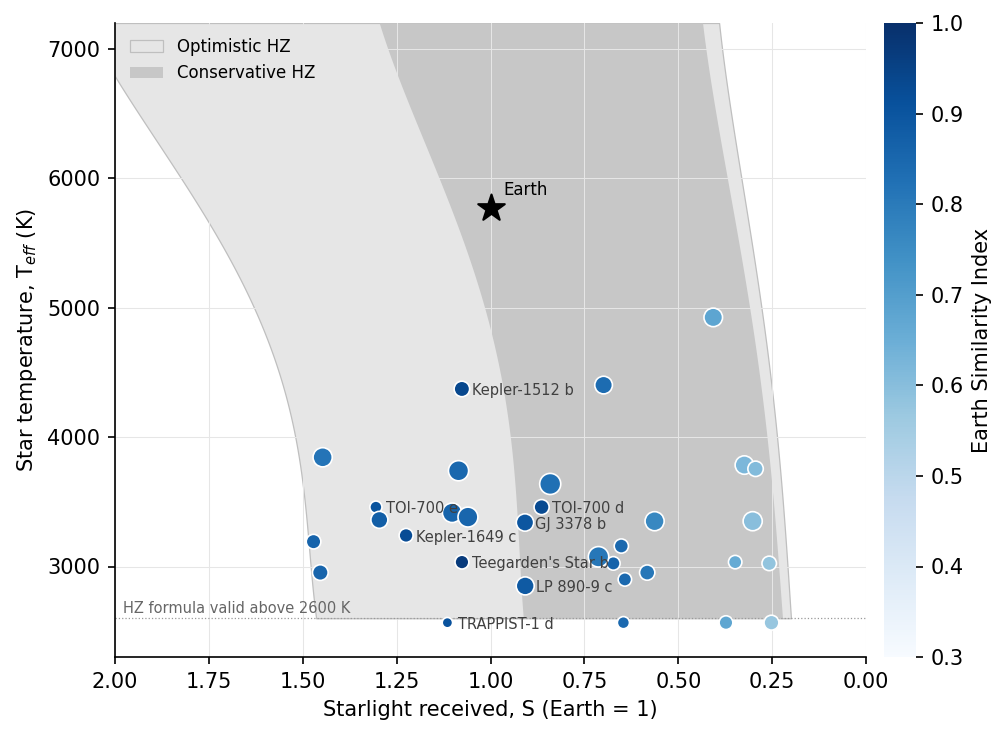

In [60]:
LABEL_TOP = 8   # direct-label only the top-N by ESI (keeps the figure readable)

fig, ax = plt.subplots(figsize=(7, 5), dpi=150)
tg = np.linspace(2600, 7200, 300)
ax.fill_betweenx(tg, hz_limit(tg, "recent_venus"), hz_limit(tg, "early_mars"),
                 color="0.90", ec="0.75", lw=0.6, label="Optimistic HZ")
ax.fill_betweenx(tg, hz_limit(tg, "runaway_greenhouse"), hz_limit(tg, "maximum_greenhouse"),
                 color="0.78", lw=0, label="Conservative HZ")

sc = ax.scatter(hz["S"], hz["st_teff"], s=40 * hz["R"]**2, c=hz["ESI"],
                cmap="Blues", vmin=0.3, vmax=1.0,
                edgecolor="white", linewidth=0.8, zorder=3)
ax.scatter([1], [5772], marker="*", s=180, color="black", zorder=4)
ax.annotate("Earth", (1, 5772), xytext=(6, 6), textcoords="offset points", fontsize=8)

for _, r in hz.head(LABEL_TOP).iterrows():
    ax.annotate(r["pl_name"], (r["S"], r["st_teff"]), xytext=(5, -3),
                textcoords="offset points", fontsize=7, color="0.25")

ax.set_xlim(2.0, 0.0)          # reversed: hot (inner) on the left
ax.set_ylim(2300, 7200)
ax.axhline(2600, color="0.6", lw=0.6, ls=":")
ax.text(1.98, 2620, "HZ formula valid above 2600 K", fontsize=7, color="0.4", va="bottom")
ax.set_xlabel("Starlight received, S (Earth = 1)")
ax.set_ylabel("Star temperature, T$_{eff}$ (K)")
for side in ("top", "right"): ax.spines[side].set_visible(False)
ax.grid(color="0.9", lw=0.5)
cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label("Earth Similarity Index")
cb.outline.set_visible(False)
ax.legend(loc="upper left", frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(f"P2_HZ_diagram_{TODAY}.png", dpi=300)
plt.show()

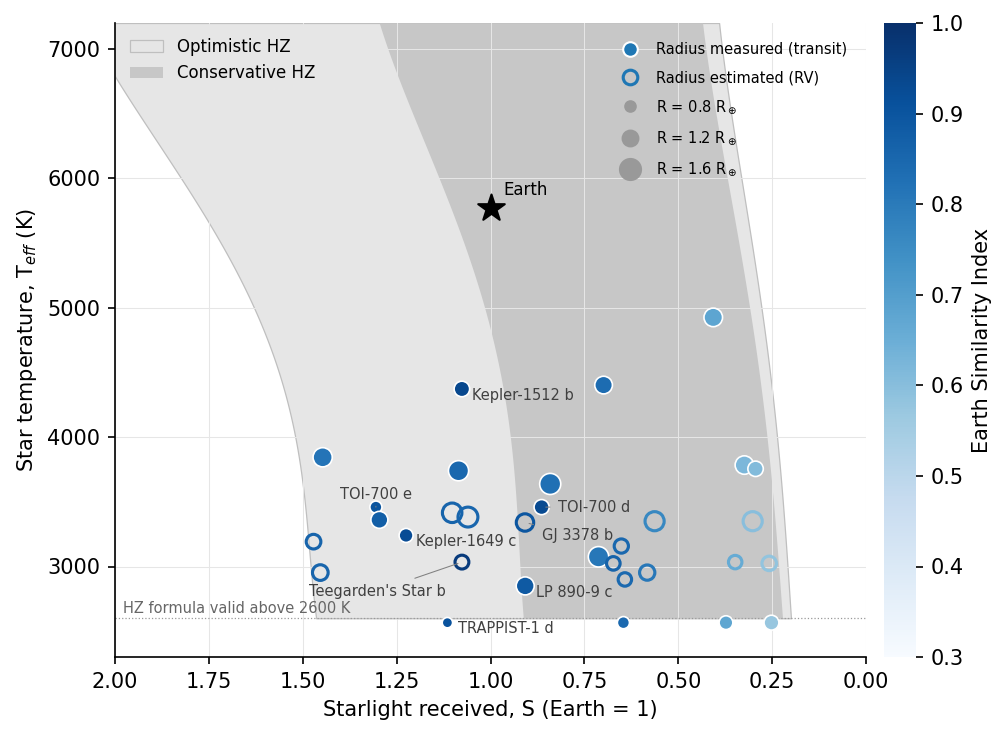

In [61]:
from matplotlib.lines import Line2D

LABEL_TOP = 8   # direct-label only the top-N by ESI (keeps the figure readable)

# custom label positions (offset in points, horizontal alignment) to avoid overlaps
LABEL_POS = {
    "TOI-700 e":          ((0, 6),   "center"),
    "Teegarden's Star b": ((-8, -14), "right"),   # down-left, into the empty space
    "TOI-700 d":          ((8, 0),   "left"),     # straight right, below the big dot
    "GJ 3378 b":          ((8, -6),  "left"),
}
fig, ax = plt.subplots(figsize=(7, 5), dpi=150)
tg = np.linspace(2600, 7200, 300)
ax.fill_betweenx(tg, hz_limit(tg, "recent_venus"), hz_limit(tg, "early_mars"),
                 color="0.90", ec="0.75", lw=0.6, label="Optimistic HZ")
ax.fill_betweenx(tg, hz_limit(tg, "runaway_greenhouse"), hz_limit(tg, "maximum_greenhouse"),
                 color="0.78", lw=0, label="Conservative HZ")

# planets: filled = radius measured by transit; open = radius estimated (RV, archive M-R)
meas = hz["R_source"] == "measured (transit)"
sc = ax.scatter(hz.loc[meas, "S"], hz.loc[meas, "st_teff"],
                s=40 * hz.loc[meas, "R"]**2, c=hz.loc[meas, "ESI"],
                cmap="Blues", vmin=0.3, vmax=1.0,
                edgecolor="white", linewidth=0.8, zorder=3)
ax.scatter(hz.loc[~meas, "S"], hz.loc[~meas, "st_teff"],
           s=40 * hz.loc[~meas, "R"]**2, facecolors="none",
           edgecolors=plt.cm.Blues(np.clip((hz.loc[~meas, "ESI"] - 0.3) / 0.7, 0, 1)),
           linewidths=1.5, zorder=3)

ax.scatter([1], [5772], marker="*", s=180, color="black", zorder=4)
ax.annotate("Earth", (1, 5772), xytext=(6, 6), textcoords="offset points", fontsize=8)

for _, r in hz.head(LABEL_TOP).iterrows():
    offset, ha = LABEL_POS.get(r["pl_name"], ((5, -3), "left"))
    leader = dict(arrowstyle="-", color="0.5", lw=0.5) if r["pl_name"] in LABEL_POS else None
    ax.annotate(r["pl_name"], (r["S"], r["st_teff"]), xytext=offset, ha=ha, va="center",
                textcoords="offset points", fontsize=7, color="0.25", arrowprops=leader)

ax.set_xlim(2.0, 0.0)          # reversed: hot (inner) on the left
ax.set_ylim(2300, 7200)
ax.axhline(2600, color="0.6", lw=0.6, ls=":")
ax.text(1.98, 2620, "HZ formula valid above 2600 K", fontsize=7, color="0.4", va="bottom")
ax.set_xlabel("Starlight received, S (Earth = 1)")
ax.set_ylabel("Star temperature, T$_{eff}$ (K)")
for side in ("top", "right"): ax.spines[side].set_visible(False)
ax.grid(color="0.9", lw=0.5)
cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label("Earth Similarity Index")
cb.outline.set_visible(False)

# legend 1: HZ bands (top left)
leg1 = ax.legend(loc="upper left", frameon=False, fontsize=8)
ax.add_artist(leg1)

# legend 2: radius source + dot size (top right)
handles = [
    Line2D([], [], marker="o", ls="", color="tab:blue", mec="white", ms=7,
           label="Radius measured (transit)"),
    Line2D([], [], marker="o", ls="", mfc="none", mec="tab:blue", mew=1.5, ms=7,
           label="Radius estimated (RV)"),
] + [
    Line2D([], [], marker="o", ls="", color="0.6", ms=np.sqrt(40) * R,
           label=f"R = {R} R$_\\oplus$")
    for R in (0.8, 1.2, 1.6)
]
ax.legend(handles=handles, loc="upper right", frameon=False, fontsize=7,
          labelspacing=0.9, borderpad=0.8)

fig.tight_layout()
fig.savefig(f"P2_HZ_diagram_{TODAY}.png", dpi=300)
plt.show()

## D. Project 1: Fact-check a viral claim

`lookup("Kepler-452b")` returns the archive values for one planet. Names are matched loosely
(`Kepler-452b`, `kepler 452 b`, `KEPLER-452 B` all work). If the planet is **not** in the archive,
the closest real names are suggested. That is how a made-up planet such as *Kepler-1602c* gets caught.

In [ ]:
def _norm(name):
    return re.sub(r"[\s\-_]", "", str(name)).lower()

_NAME_INDEX = {_norm(n): n for n in df["pl_name"]}

def find_planet(name):
    key = _norm(name)
    if key in _NAME_INDEX:
        return _NAME_INDEX[key], []
    host = key[:-1]   # same star = name without the planet letter
    same_host = [n for k, n in _NAME_INDEX.items() if k[:-1] == host]
    close = difflib.get_close_matches(key, _NAME_INDEX.keys(), n=5, cutoff=0.8)
    return None, same_host + [_NAME_INDEX[c] for c in close if _NAME_INDEX[c] not in same_host]

def lookup(name):
    pl, suggestions = find_planet(name)
    if pl is None:
        print(f"'{name}' is NOT in the NASA Exoplanet Archive ({TODAY}).")
        if suggestions:
            print("   Closest real planets:", ", ".join(suggestions))
        return None
    r = df[df["pl_name"] == pl].iloc[0]
    out = {
        "archive name": pl,
        "distance (ly)": r["dist_ly"],
        "radius (R_earth)": r["pl_rade"], "radius source": r["R_source"],
        "diameter (km)": r["pl_rade"] * 2 * EARTH_RADIUS_KM,
        "mass (M_earth)": r["pl_bmasse"],
        "mass type": r["pl_bmassprov"],
        "orbital period (days)": r["pl_orbper"],
        "orbit (AU)": r["pl_orbsmax"],
        "starlight S (Earth=1)": r["S"],
        "T_eq (°C, A=0.3)": r["T_eq_C"],
        "ESI": r["ESI"],
        "rocky? (R ≤ 1.6)": bool(r["pl_rade"] <= RADIUS_MAX) if pd.notna(r["pl_rade"]) else "radius unknown",
        "habitable zone": r["HZ"],
        "star": f"{r['st_spectype']}  T_eff={r['st_teff']} K",
        "discovery": f"{r['discoverymethod']} {r['disc_year']}",
    }
    return pd.Series(out)

lookup("Kepler-452b")

In [ ]:
lookup("Kepler-1602c")   # the made-up planet from the first infographic

In [ ]:
pd.DataFrame({p: lookup(p) for p in ["Kepler-442b", "Kepler-186f", "TRAPPIST-1e"]})

### Check a whole claims log
1. Fill in the **claims log** (Project 1 sheet), then download it as **CSV** or **Excel** and upload it here (folder icon on the left).
2. Set `CLAIMS_FILE` below and run the cell.

Recognised values in the `quantity` column:
`distance_ly`, `radius_earth`, `diameter_km`, `mass_earth`, `orbital_period_d`, `eq_temp_C`, `eq_temp_K`, `star_temp_K`, `gravity_g`, `existence`.
Temperatures are compared in **kelvin** (a % error in °C is meaningless around 0 °C).

In [ ]:
CLAIMS_FILE = "claims_log.csv"   # or "claims_log.xlsx"

def archive_value(pl, quantity):
    r = df[df["pl_name"] == pl].iloc[0]
    q = quantity
    if q == "distance_ly":      return r["dist_ly"]
    if q == "radius_earth":     return r["pl_rade"]
    if q == "diameter_km":      return r["pl_rade"] * 2 * EARTH_RADIUS_KM
    if q == "mass_earth":       return r["pl_bmasse"]
    if q == "orbital_period_d": return r["pl_orbper"]
    if q in ("eq_temp_K", "eq_temp_C"): return r["T_eq_K"]
    if q == "star_temp_K":      return r["st_teff"]
    if q == "gravity_g":        # g = M / R^2 (Earth units), only if both measured
        return r["pl_bmasse"] / r["pl_rade"]**2 if pd.notna(r["pl_rade"]) else np.nan
    return np.nan

def check_claims(claims):
    # the sheet's own (hand-copied) values are kept, renamed, so they can be compared
    claims = claims.rename(columns={"archive_value": "archive_value_sheet",
                                    "percent_error": "percent_error_sheet"})
    rows = []
    for _, c in claims.iterrows():
        pl, sugg = find_planet(c["planet_as_claimed"])
        q = str(c.get("quantity", "")).strip()
        res = {"exists_in_archive": pl is not None, "archive_name": pl,
               "suggestions": ", ".join(sugg), "archive_value": np.nan, "percent_error": np.nan}
        if pl is not None and q not in ("", "existence", "nan"):
            claimed = pd.to_numeric(c.get("claimed_value"), errors="coerce")
            if q == "eq_temp_C" and pd.notna(claimed):
                claimed = claimed + 273.15          # compare in kelvin
            true = archive_value(pl, q)
            res["archive_value"] = round(true - 273.15, 1) if q == "eq_temp_C" else true
            if pd.notna(claimed) and pd.notna(true) and true != 0:
                res["percent_error"] = round(abs(claimed - true) / abs(true) * 100, 1)
        rows.append(res)
    return pd.concat([claims.reset_index(drop=True), pd.DataFrame(rows)], axis=1)

try:
    claims = (pd.read_excel(CLAIMS_FILE) if CLAIMS_FILE.endswith("xlsx")
              else pd.read_csv(CLAIMS_FILE))
    checked = check_claims(claims)
    checked.to_csv(f"P1_claims_checked_{TODAY}.csv", index=False)
    display(checked[["claim_id", "planet_as_claimed", "quantity", "claimed_value",
                     "exists_in_archive", "archive_value", "percent_error", "error_type"]])
except FileNotFoundError:
    print(f"Upload {CLAIMS_FILE} first (folder icon on the left).")

### Summary for the paper: errors by type

In [ ]:
if "checked" in globals():
    counts = checked["error_type"].value_counts()
    print(counts.to_string())
    print(f"\nPosts checked: {checked['source_post'].nunique()} · claims: {len(checked)}")
    print(f"Median % error (numeric claims): {checked['percent_error'].median():.1f}%")

    fig, ax = plt.subplots(figsize=(6, 0.4 * len(counts) + 1), dpi=150)
    ax.barh(counts.index[::-1], counts.values[::-1], color="#2a6fb0", height=0.6)
    for y, v in enumerate(counts.values[::-1]):
        ax.text(v + 0.1, y, str(v), va="center", fontsize=8)
    ax.set_xlabel("Number of claims")
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    fig.tight_layout()
    fig.savefig(f"P1_error_types_{TODAY}.png", dpi=300)
    plt.show()

## Files this notebook saves (download them from the folder panel)
* `pscomppars_<date>.csv`: the raw archive table (quote the date in the paper)
* `P2_rocky_HZ_ranked_<date>.csv`: Project 2 ranking
* `P2_HZ_diagram_<date>.png`: Project 2 figure (300 dpi)
* `P1_claims_checked_<date>.csv`, `P1_error_types_<date>.png`: Project 1 results

**References:** Kopparapu et al. 2014, ApJL 787, L29 · Schulze-Makuch et al. 2011, Astrobiology 11, 1041 (ESI) · Rogers 2015, ApJ 801, 41 · Chen & Kipping 2017, ApJ 834, 17 · NASA Exoplanet Archive (doi:10.26133/NEA13)